# Chapter 15: Choice Under Risk, Ambiguity, and Probability Weighting

This notebook reruns four worked examples from the chapter: the Allais common consequence, a loss-averse chooser facing a favorable bet (prospect theory), the Ellsberg urns under worst-case priors, and inverse-S probability weights. Every example is hypothetical, as in the book; a few extra input values are added for comparison, and the Allais utility ratios are constructed because the book gives none.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def expected_value(outcomes, probs):
    """Probability-weighted mean of outcomes. expected-utility-theorem: E[X] = 0.5(100) + 0.5(25) = 62.5."""
    if abs(sum(probs) - 1.0) > 1e-9:
        raise ValueError("probabilities must sum to one")
    return float(sum(p * x for p, x in zip(probs, outcomes)))


def expected_utility(probs, utils):
    """Probability-weighted utility. expected-utility-theorem: EU(A) = 0.5 sqrt(100) + 0.5 sqrt(25) = 7.5."""
    if abs(sum(probs) - 1.0) > 1e-9:
        raise ValueError("probabilities must sum to one")
    return float(sum(p * v for p, v in zip(probs, utils)))


def prospect_value(outcomes, probs, alpha=1.0, lam=2.25, w=None):
    """Prospect-theory value sum w_i v(x_i), with v(x) = x^alpha for gains and -lam (-x)^alpha for losses.

    Principle: prospect-theory. Book (ch015): gain 150, loss 100, alpha 1, lam 2, weights 0.5 gives -25;
    gain 220 gives 10. ``w`` is an optional list of decision weights (default: the probabilities).
    """
    weights = list(probs) if w is None else list(w)
    total = 0.0
    for x, wi in zip(outcomes, weights):
        v = x ** alpha if x >= 0 else -lam * (-x) ** alpha
        total += wi * v
    return total


def maxmin_value(prize, p_low, p_high):
    """Maxmin expected utility of red and black bets when the red share lies in [p_low, p_high].

    Principle: ellsberg-paradox. Book (ch015): prize 100, P = [0.2, 0.8] gives red 20 and black 20.
    Returns {"red": prize * p_low, "black": prize * (1 - p_high)}.
    """
    return {"red": prize * p_low, "black": prize * (1 - p_high)}


def weighted_value(w, x):
    """Decision-weighted value w(p) x of a single-prize gamble with linear value.

    Principle: inverse-s-probability-weighting. Book (ch015): 0.05(1,000) = 50 and 0.65(100) = 65.
    """
    return w * x


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(expected_value=expected_value, expected_utility=expected_utility)


behavioral = SimpleNamespace(prospect_value=prospect_value, maxmin_value=maxmin_value, weighted_value=weighted_value)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'allais-paradox': {'p_5': 0.1,
                    'p_1': 0.89,
                    'p_0': 0.01,
                    'p_c': 0.11,
                    'p_d': 0.1,
                    'u0': 0,
                    'indifference_ratio': 1.1},
 'prospect-theory': {'gain': 150,
                     'loss': 100,
                     'alpha': 1,
                     'lam': 2,
                     'weight': 0.5,
                     'V': -25,
                     'ev': 25,
                     'gain_2': 220,
                     'V_2': 10,
                     'threshold': 200,
                     'ev_threshold': 100},
 'ellsberg-paradox': {'prize': 100,
                      'known': 50,
                      'p_low': 0.2,
                      'p_high': 0.8,
                      'red': 20,
                      'black': 20,
                      'revealed': 0.65,
                      'red_revealed': 65,
                      'black_revealed': 35,
                      'gap': 30},
 'inverse-s-probability-weighting': {'rare_p': 0.01,
                                     'rare_prize': 1000,
                                     'rare_sure': 30,
                                     'rare_linear': 10,
                                     'rare_w': 0.05,
                                     'rare_weighted': 50,
                                     'likely_p': 0.8,
                                     'likely_prize': 100,
                                     'likely_sure': 70,
                                     'likely_linear': 80,
                                     'likely_w': 0.65,
                                     'likely_weighted': 65},
 'constructed': {'allais-paradox': {'ratio': [1.0, 1.1, 1.2, 1.5], 'default_ratio': 1.2},
                 'prospect-theory': {'lam': [1, 1.5, 2.5]},
                 'ellsberg-paradox': {'low': [0.35, 0.5]},
                 'inverse-s-probability-weighting': {'rare_mid': 0.03, 'likely_mid': 0.725}}}


def allais_picture(ratio=1.2, common=0.89):
    u1, u5 = 1.0, float(ratio)
    if common:
        names = ("A", "B")
        eu_x = choice.expected_utility([1.0], [u1])
        eu_y = choice.expected_utility([0.10, 0.89, 0.01], [u5, u1, 0.0])
        desc_x, desc_y = "A: 1 million for certain", "B: 5m at 0.10, 1m at 0.89, 0 at 0.01"
    else:
        names = ("C", "D")
        eu_x = choice.expected_utility([0.11, 0.89], [u1, 0.0])
        eu_y = choice.expected_utility([0.10, 0.90], [u5, 0.0])
        desc_x, desc_y = "C: 1m at 0.11, else 0", "D: 5m at 0.10, else 0"
    safe, risky = 0.11 * u1, 0.10 * u5
    winner, tie = tie_or_winner(names[0], eu_x, names[1], eu_y)
    fig, ax = new_figure()
    bar_compare(ax, [desc_x, desc_y], [eu_x, eu_y], colors=["teal", "gold"],
                value_labels=[f"EU = {num(eu_x, 3)}", f"EU = {num(eu_y, 3)}"],
                ylabel="Expected utility, u(1) = 1", xlabel=f"Menu {'1' if common else '2'} options")
    ax.set_ylim(0, 1.32)
    ax.text(0.98, 0.95, f"0.11u(1) = {num(safe, 3)} vs 0.10u(5) = {num(risky, 3)}", transform=ax.transAxes,
            ha="right", va="top", fontsize=10.5, color=PALETTE["ink"])
    menu = "menu 1" if common else "menu 2"
    if tie:
        verdict = f"{names[0]} and {names[1]} tie: expected utility is indifferent in {menu}"
        both = "Both menus are ties at this ratio."
    else:
        verdict = f"{winner} has higher expected utility in {menu}"
        safe_wins = safe > risky
        both = (f"In both menus expected utility picks the {'safer' if safe_wins else 'riskier'} option "
                f"({'A and C' if safe_wins else 'B and D'}), so the observed pair A and D cannot occur.")
    metrics = {"u(5)/u(1)": num(ratio, 1), f"EU({names[0]})": num(eu_x, 3), f"EU({names[1]})": num(eu_y, 3),
               "0.11u(1)": num(safe, 3), "0.10u(5)": num(risky, 3),
               "Expected-utility choice": "tie" if tie else winner}
    if common:
        lines = [f"EU(A) = u(1) = {num(eu_x, 3)}",
                 f"EU(B) = 0.10 x {num(u5, 1)} + 0.89 x 1 + 0.01 x 0 = {num(risky, 3)} + 0.890 = {num(eu_y, 3)}"]
    else:
        lines = [f"EU(C) = 0.11 x 1 = {num(eu_x, 3)}", f"EU(D) = 0.10 x {num(u5, 1)} = {num(eu_y, 3)}"]
    steps = lines + [f"Difference = 0.11u(1) - 0.10u(5) = {num(safe, 3)} - {num(risky, 3)} = {num(safe - risky, 3)}",
                     f"{verdict}"]
    interp = (f"With u(0) = 0, u(1) = 1 and u(5) = {num(u5, 1)}: {lines[0]} and {lines[1]}. Either way the comparison "
              f"reduces to 0.11u(1) = {num(safe, 3)} against 0.10u(5) = {num(risky, 3)}, because the common 0.89 "
              f"chance of 1 million cancels. {verdict}. {both}")
    alt = (f"Two bars for {menu} at u(5)/u(1) = {num(ratio, 1)}: {names[0]} has expected utility {num(eu_x, 3)} and "
           f"{names[1]} has {num(eu_y, 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def prospect_picture(gain=150, lam=2):
    loss = BV["prospect-theory"]["loss"]
    V = behavioral.prospect_value([gain, -loss], [0.5, 0.5], alpha=1, lam=lam)
    ev = choice.expected_value([gain, -loss], [0.5, 0.5])
    g_star = lam * loss
    decision, tie = tie_or_winner("accept", V, "reject", 0.0)
    fig, ax = new_figure()
    xs = np.linspace(-130, 260, 300)
    ax.plot(xs, [x if x >= 0 else lam * x for x in xs], color=PALETTE["navy"], linewidth=2.2)
    ax.plot(xs, xs, color=PALETTE["grey"], linewidth=1.2, linestyle="dashed")
    ax.text(0.03, 0.95, "dashed: linear value v = x", transform=ax.transAxes, ha="left", va="top", fontsize=10.5,
            color=PALETTE["grey"])
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.axvline(0, color=PALETTE["grey"], linewidth=1)
    mark(ax, gain, gain, f"gain {num(gain, 0)}: v = {num(gain, 0)}", col="teal", dx=-8, dy=8, ha="right")
    mark(ax, -loss, -lam * loss, f"loss 100: v = {num(-lam * loss, 0)}", col="terracotta", dx=8, dy=-4, va="top")
    ax.text(0.98, 0.06, f"V = 0.5({num(gain, 0)}) + 0.5({num(-lam * loss, 0)}) = {num(V, 0)}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=10.5, color=PALETTE["ink"])
    ax.set_xlim(-140, 270)
    ax.set_ylim(-330, 280)
    ax.set_xlabel("Outcome relative to current wealth")
    ax.set_ylabel(f"Value v(x), lambda = {num(lam, 1)}")
    choice_text = "indifferent (tie)" if tie else decision
    metrics = {"Prospect value V": num(V, 0), "Expected value": num(ev, 0), "Threshold gain g*": num(g_star, 0),
               "Decision": choice_text}
    if tie:
        verdict = f"V = 0, so the chooser is exactly indifferent: {num(gain, 0)} is the threshold gain"
    elif V > 0:
        verdict = f"V = {num(V, 0)} is above zero, so the chooser accepts"
    else:
        verdict = f"V = {num(V, 0)} is below zero, so the chooser rejects despite expected value {num(ev, 0)}"
    steps = [f"V = 0.5({num(gain, 0)}) + 0.5[-{num(lam, 1)}(100)] = {num(0.5 * gain, 0)} - {num(0.5 * lam * loss, 0)} = {num(V, 0)}",
             f"Expected value = 0.5({num(gain, 0)}) - 0.5(100) = {num(ev, 0)}",
             f"Threshold: 0.5g* - 0.5({num(lam, 1)})(100) = 0 gives g* = {num(g_star, 0)}",
             verdict]
    interp = (f"With alpha = 1 and weights 0.5, V = 0.5({num(gain, 0)}) + 0.5[-{num(lam, 1)}(100)] = "
              f"{num(0.5 * gain, 0)} - {num(0.5 * lam * loss, 0)} = {num(V, 0)}. {verdict}. The gain needed to accept "
              f"is g* = {num(lam, 1)} x 100 = {num(g_star, 0)}, against 100 under expected value.")
    alt = (f"Kinked value function with loss slope {num(lam, 1)}. The gain {num(gain, 0)} has value {num(gain, 0)} and "
           f"the loss of 100 has value {num(-lam * loss, 0)}; the prospect value is {num(V, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ellsberg_picture(low=0.2, reveal="no"):
    prize = BV["ellsberg-paradox"]["prize"]
    known = 0.5 * prize
    if reveal == "no":
        vals = behavioral.maxmin_value(prize, low, 1 - low)
        lines = [f"Known urn K: 0.5 x 100 = {num(known, 0)}",
                 f"Ambiguous red: worst case {num(low, 2)}(100) = {num(vals['red'], 0)}",
                 f"Ambiguous black: worst case 1 - {num(1 - low, 2)} = {num(1 - (1 - low), 2)}, so "
                 f"{num(1 - (1 - low), 2)}(100) = {num(vals['black'], 0)}"]
        setting = f"prior set [{num(low, 2)}, {num(1 - low, 2)}]"
    else:
        vals = behavioral.maxmin_value(prize, 0.65, 0.65)
        lines = [f"Known urn K: 0.5 x 100 = {num(known, 0)}",
                 f"Revealed red: 0.65 x 100 = {num(vals['red'], 0)}",
                 f"Revealed black: 0.35 x 100 = {num(vals['black'], 0)}"]
        setting = "revealed composition of 65 red and 35 black"
    red_w, red_tie = tie_or_winner("ambiguous urn", vals["red"], "K", known)
    blk_w, blk_tie = tie_or_winner("ambiguous urn", vals["black"], "K", known)

    def say(color_name, w, tie):
        return f"{color_name}: {'tie between the urns' if tie else ('bet on ' + w)}"

    fig, ax = new_figure()
    bar_compare(ax, ["Known urn K", "Ambiguous red", "Ambiguous black"], [known, vals["red"], vals["black"]],
                colors=["teal", "terracotta", "ink"], value_labels=[num(v, 0) for v in (known, vals["red"], vals["black"])],
                ylabel="Value of the bet (prize 100)", xlabel=setting.capitalize())
    ax.set_ylim(0, 85)
    hline(ax, known, col="teal")
    metrics = {"Known urn": num(known, 0), "Red bet on A": num(vals["red"], 0), "Black bet on A": num(vals["black"], 0),
               "Maxmin gap per color": num(known - min(vals["red"], vals["black"]), 0) if reveal == "no" else "none",
               "Red choice": "tie" if red_tie else red_w, "Black choice": "tie" if blk_tie else blk_w}
    steps = lines + [say("Red", red_w, red_tie) + "; " + say("black", blk_w, blk_tie)]
    if reveal == "no":
        gap = known - vals["red"]
        tail = (f"Both ambiguous bets are worth {num(vals['red'], 0)}, so Maya prefers K for both colors, a maxmin gap "
                f"of {num(gap, 0)} each. No single prior can explain betting on K for red and for black."
                if gap > 0 else "With a single prior of 0.5 the urns are worth the same: no ambiguity, no preference.")
    else:
        tail = "One known probability explains both choices: red on A beats K, black on A loses, and the paradox disappears."
    interp = f"With the {setting}: " + "; ".join(lines) + ". " + tail
    alt = (f"Three bars: known urn {num(known, 0)}, ambiguous red {num(vals['red'], 0)}, ambiguous black "
           f"{num(vals['black'], 0)}, with the {setting}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


CASES = {"rare": (0.01, 1_000, 30), "likely": (0.80, 100, 70)}


def weighting_picture(case="rare", w="book"):
    bv = BV["inverse-s-probability-weighting"]
    mid = BV["constructed"]["inverse-s-probability-weighting"]
    p, prize, sure = CASES[case]
    weight = {"linear": p, "book": bv[f"{case}_w"], "mid": mid[f"{case}_mid"]}[w]
    value = behavioral.weighted_value(weight, prize)
    winner, tie = tie_or_winner("gamble", value, "sure amount", sure)
    fig, (ax, bx) = new_figure(ncols=2)
    ps = np.linspace(0, 1, 200)
    ax.plot(ps, ps, color=PALETTE["grey"], linestyle="dashed", linewidth=1.4)
    label(ax, 0.3, 0.3, "w(p) = p", col="grey", dx=-8, dy=8, ha="right")
    for c, (pp, _, _) in CASES.items():
        ax.scatter([pp], [bv[f"{c}_w"]], s=30, color=PALETTE["light"], zorder=4)
    mark(ax, p, weight, f"w({num(p, 2)}) = {num(weight, 3 if weight < 0.1 or round(weight, 2) != weight else 2)}", col="navy",
         dx=8 if case == "rare" else -8, dy=8 if case == "rare" else -10, ha="left" if case == "rare" else "right",
         va="bottom" if case == "rare" else "top")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Probability p")
    ax.set_ylabel("Decision weight w(p)")
    bar_compare(bx, ["Gamble", "Sure amount"], [value, sure], colors=["navy", "teal"],
                value_labels=[num(value, 1 if value % 1 else 0), num(sure, 0)], ylabel="Value",
                xlabel=f"{num(100 * p, 0)}% chance of {num(prize, 0)} or {num(sure, 0)} for certain")
    mode = {"linear": "linear weight", "book": "book weight", "mid": "midpoint weight"}[w]
    verdict = "the gamble and the sure amount tie" if tie else f"the {winner} wins"
    shown = num(value, 1 if value % 1 else 0)
    metrics = {"Decision weight": num(weight, 3), "Weighted value": shown, "Sure amount": num(sure, 0),
               "Choice": "tie" if tie else winner}
    steps = [f"Weight ({mode}): w({num(p, 2)}) = {num(weight, 3)}",
             f"Weighted value = {num(weight, 3)} x {num(prize, 0)} = {shown}",
             f"Compare with {num(sure, 0)} for certain: {verdict}"]
    interp = (f"With {mode} w({num(p, 2)}) = {num(weight, 3)}, the gamble is worth {num(weight, 3)} x {num(prize, 0)} "
              f"= {shown} against {num(sure, 0)} for certain, so {verdict}. The probability itself is unchanged; only "
              f"the weight it receives differs.")
    alt = (f"Left: the 45 degree line with the weight {num(weight, 3)} at p = {num(p, 2)}. Right: bars for the gamble "
           f"worth {shown} and the sure amount {num(sure, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Allais paradox: the common consequence

Prizes are 0, 1 and 5 million with $u(0)=0$, and utility is scaled so $u(1)=1$. Choosing A in menu 1 requires

$$u(1)>0.10u(5)+0.89u(1),\qquad 0.11u(1)>0.10u(5)$$

while choosing D in menu 2 requires $0.10u(5)>0.11u(1)$. The ratio $u(5)/u(1)=1.2$ is constructed.

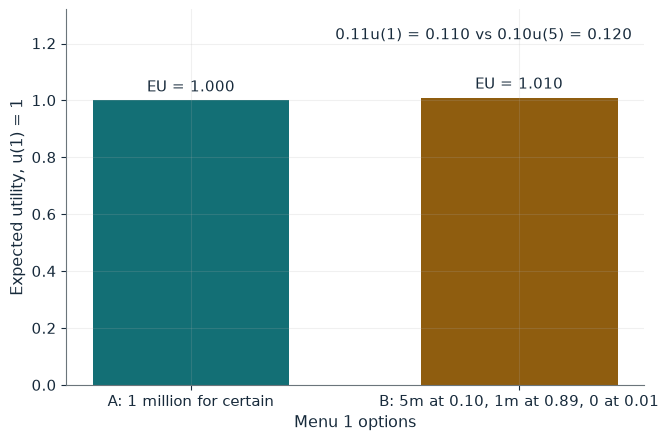

u(5)/u(1)                1.2
EU(A)                    1.000
EU(B)                    1.010
0.11u(1)                 0.110
0.10u(5)                 0.120
Expected-utility choice  B

Worked steps:
  1. EU(A) = u(1) = 1.000
  2. EU(B) = 0.10 x 1.2 + 0.89 x 1 + 0.01 x 0 = 0.120 + 0.890 = 1.010
  3. Difference = 0.11u(1) - 0.10u(5) = 0.110 - 0.120 = -0.010
  4. B has higher expected utility in menu 1

With u(0) = 0, u(1) = 1 and u(5) = 1.2: EU(A) = u(1) = 1.000 and EU(B) = 0.10 x 1.2 + 0.89 x 1 + 0.01 x 0 = 0.120 + 0.890 = 1.010. Either way the comparison reduces to 0.11u(1) = 0.110 against 0.10u(5) = 0.120, because the common 0.89 chance of 1 million cancels. B has higher expected utility in menu 1. In both menus expected utility picks the riskier option (B and D), so the observed pair A and D cannot occur.


In [2]:
show(allais_picture(ratio=1.2, common=0.89))

Change one input, `ratio`, and hold the others at the book's values:

In [3]:
sweep(allais_picture, 'ratio', [1.0, 1.1, 1.2, 1.5], {'common': 0}, ['EU(C)', 'EU(D)', 'Expected-utility choice'])

ratio | EU(C) | EU(D) | Expected-utility choice
1.0 | 0.110 | 0.100 | C
1.1 | 0.110 | 0.110 | tie
1.2 | 0.110 | 0.120 | D
1.5 | 0.110 | 0.150 | D


Whatever the ratio, menu 1 and menu 2 reduce to the same comparison of 0.11u(1) with 0.10u(5): A goes with C and B goes with D, and at a ratio of 1.1 both menus are ties. The observed pair A and D violates independence.

## 2. Prospect theory: loss aversion flips a favorable bet

A 50-50 gamble gains 150 or loses 100, with $\alpha=1$ and $\lambda=2$:

$$V=0.5(150)+0.5[-2(100)]=75-100=-25.$$

The threshold gain solves $0.5g^*-0.5(2)(100)=0$.

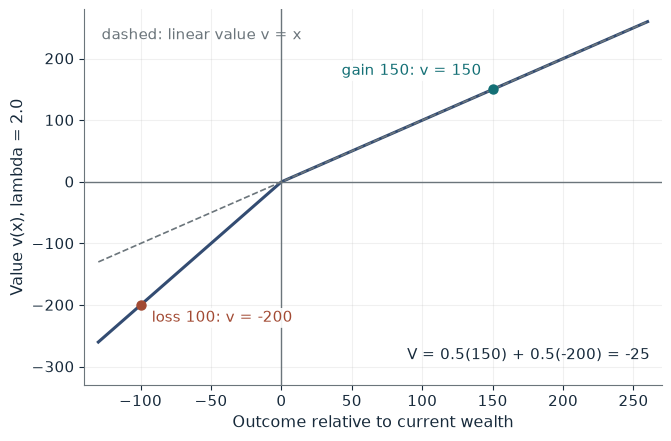

Prospect value V   -25
Expected value     25
Threshold gain g*  200
Decision           reject

Worked steps:
  1. V = 0.5(150) + 0.5[-2.0(100)] = 75 - 100 = -25
  2. Expected value = 0.5(150) - 0.5(100) = 25
  3. Threshold: 0.5g* - 0.5(2.0)(100) = 0 gives g* = 200
  4. V = -25 is below zero, so the chooser rejects despite expected value 25

With alpha = 1 and weights 0.5, V = 0.5(150) + 0.5[-2.0(100)] = 75 - 100 = -25. V = -25 is below zero, so the chooser rejects despite expected value 25. The gain needed to accept is g* = 2.0 x 100 = 200, against 100 under expected value.


In [4]:
show(prospect_picture(gain=150, lam=2))

Change one input, `lam`, and hold the others at the book's values:

In [5]:
sweep(prospect_picture, 'lam', [1, 1.5, 2, 2.5], {'gain': 150}, ['Prospect value V', 'Threshold gain g*', 'Decision'])

lam | Prospect value V | Threshold gain g* | Decision
1 | 25 | 100 | accept
1.5 | 0 | 150 | indifferent (tie)
2 | -25 | 200 | reject
2.5 | -50 | 250 | reject


The bet has expected value 25 but prospect value -25, so it is rejected. The threshold gain is lambda times the loss: 200 at lambda 2. At lambda 1.5 the 150 gain is exactly the threshold, a tie.

## 3. Ellsberg paradox: worst-case priors

Urn K holds 50 red and 50 black; urn A has an unknown composition. A correct color pays 100. With the prior set $P=[0.2,0.8]$ and maxmin evaluation:

$$0.5(100)=50,\qquad 0.2(100)=20$$

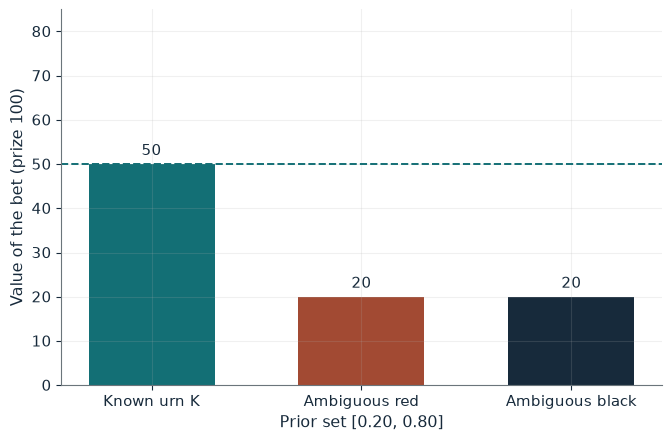

Known urn             50
Red bet on A          20
Black bet on A        20
Maxmin gap per color  30
Red choice            K
Black choice          K

Worked steps:
  1. Known urn K: 0.5 x 100 = 50
  2. Ambiguous red: worst case 0.20(100) = 20
  3. Ambiguous black: worst case 1 - 0.80 = 0.20, so 0.20(100) = 20
  4. Red: bet on K; black: bet on K

With the prior set [0.20, 0.80]: Known urn K: 0.5 x 100 = 50; Ambiguous red: worst case 0.20(100) = 20; Ambiguous black: worst case 1 - 0.80 = 0.20, so 0.20(100) = 20. Both ambiguous bets are worth 20, so Maya prefers K for both colors, a maxmin gap of 30 each. No single prior can explain betting on K for red and for black.


In [6]:
show(ellsberg_picture(low=0.2, reveal='no'))

Change one input, `low`, and hold the others at the book's values:

In [7]:
sweep(ellsberg_picture, 'low', [0.2, 0.35, 0.5], {'reveal': 'no'}, ['Red bet on A', 'Black bet on A', 'Maxmin gap per color'])

low | Red bet on A | Black bet on A | Maxmin gap per color
0.2 | 20 | 20 | 30
0.35 | 35 | 35 | 15
0.5 | 50 | 50 | 0


Both ambiguous bets are worth 20, so K wins for both colors with a gap of 30 each. Revealing 65 red (`reveal='65'`) gives 65 and 35: one known probability explains both choices.

## 4. Inverse-S probability weighting

Value is linear in gains. A 1 percent chance of 1,000 against 30 for certain, and an 80 percent chance of 100 against 70 for certain:

$$0.01(1{,}000)=10,\qquad 0.05(1{,}000)=50,\qquad 0.80(100)=80,\qquad 0.65(100)=65$$

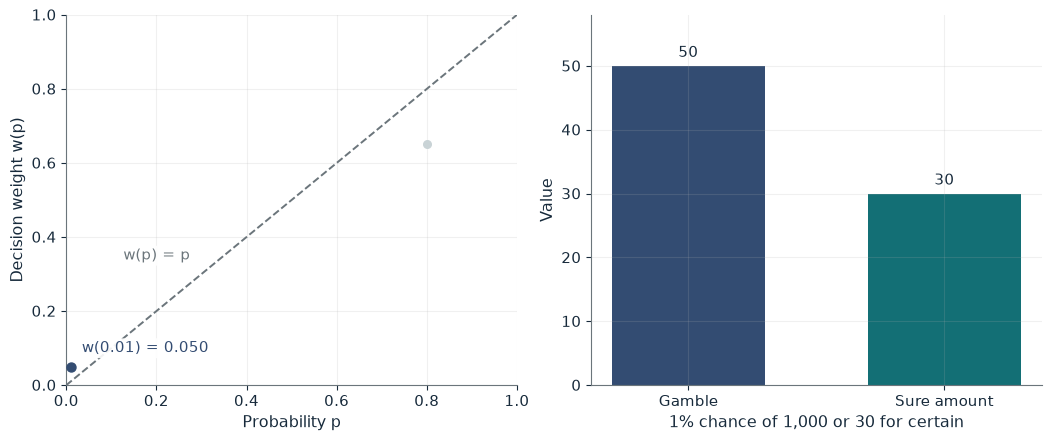

Decision weight  0.050
Weighted value   50
Sure amount      30
Choice           gamble

Worked steps:
  1. Weight (book weight): w(0.01) = 0.050
  2. Weighted value = 0.050 x 1,000 = 50
  3. Compare with 30 for certain: the gamble wins

With book weight w(0.01) = 0.050, the gamble is worth 0.050 x 1,000 = 50 against 30 for certain, so the gamble wins. The probability itself is unchanged; only the weight it receives differs.


In [8]:
show(weighting_picture(case='rare', w='book'))

Change one input, `w`, and hold the others at the book's values:

In [9]:
sweep(weighting_picture, 'w', ['linear', 'mid', 'book'], {'case': 'likely'}, ['Decision weight', 'Weighted value', 'Choice'])

w | Decision weight | Weighted value | Choice
linear | 0.800 | 80 | gamble
mid | 0.725 | 72.5 | gamble
book | 0.650 | 65 | sure amount


With the book's weights the rare prize is worth 50 and beats 30, while the likely prize is worth 65 and loses to 70. The constructed midpoint weight 0.03 makes the rare case an exact tie at 30.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

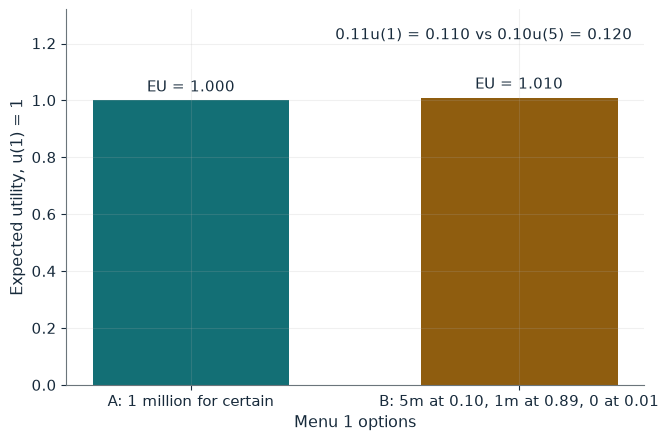

u(5)/u(1)                1.2
EU(A)                    1.000
EU(B)                    1.010
0.11u(1)                 0.110
0.10u(5)                 0.120
Expected-utility choice  B

Worked steps:
  1. EU(A) = u(1) = 1.000
  2. EU(B) = 0.10 x 1.2 + 0.89 x 1 + 0.01 x 0 = 0.120 + 0.890 = 1.010
  3. Difference = 0.11u(1) - 0.10u(5) = 0.110 - 0.120 = -0.010
  4. B has higher expected utility in menu 1

With u(0) = 0, u(1) = 1 and u(5) = 1.2: EU(A) = u(1) = 1.000 and EU(B) = 0.10 x 1.2 + 0.89 x 1 + 0.01 x 0 = 0.120 + 0.890 = 1.010. Either way the comparison reduces to 0.11u(1) = 0.110 against 0.10u(5) = 0.120, because the common 0.89 chance of 1 million cancels. B has higher expected utility in menu 1. In both menus expected utility picks the riskier option (B and D), so the observed pair A and D cannot occur.


In [10]:
show(allais_picture(ratio=1.2, common=0.89))

## Practice

**1.** At what ratio u(5)/u(1) is expected utility indifferent between A and B?

<details><summary>Answer</summary>

0.11u(1) = 0.10u(5), so u(5)/u(1) = 0.11 / 0.10 = 1.1.

</details>

**2.** With lambda = 2.5 and a loss of 100, what gain makes the 50-50 gamble acceptable?

<details><summary>Answer</summary>

0.5g* = 0.5(2.5)(100), so g* = 250; any gain above 250 is accepted.

</details>

**3.** What weight w(0.80) makes the chooser indifferent between 80 percent of 100 and 70 for certain?

<details><summary>Answer</summary>

w x 100 = 70, so w = 0.70.

</details>